## Veri seti için ideal küme sayısını bulunuz ve kümeleyiniz.

In [0]:
# https://raw.githubusercontent.com/erkansirin78/datasets/master/Mall_Customers.csv

In [0]:
# Read dataset
from pyspark import SparkFiles
Mall_Customers ="https://github.com/erkansirin78/datasets/raw/master/Mall_Customers.csv"
sc.addFile(Mall_Customers)
df = spark.read.csv("file:///"+SparkFiles.get("Mall_Customers.csv"), header= True, inferSchema=True)

In [0]:
df.show(3)

+----------+------+---+------------+-------------+
|CustomerID|Gender|Age|AnnualIncome|SpendingScore|
+----------+------+---+------------+-------------+
|         1|  Male| 19|       15000|           39|
|         2|  Male| 21|       15000|           81|
|         3|Female| 20|       16000|            6|
+----------+------+---+------------+-------------+
only showing top 3 rows



In [0]:
# StrIdx object for Gender col
from pyspark.ml.feature import StringIndexer
gender_strx = StringIndexer() \
    .setHandleInvalid('skip') \
    .setInputCol("Gender") \
    .setOutputCol("gender_indexed")

In [0]:
# VA for just numeric columns
from pyspark.ml.feature import VectorAssembler

num_features_vector_asm = VectorAssembler().setHandleInvalid("skip") \
.setInputCols(['Age', 'AnnualIncome','SpendingScore']) \
.setOutputCol('numeric_unscaled_features')


In [0]:
# Scaler just for numeric columns

from pyspark.ml.feature import StandardScaler
scaler = StandardScaler().setInputCol("numeric_unscaled_features").setOutputCol("num_scaled_features")

In [0]:
# VA for all inpute (num + cat)
all_features_vector_asm = VectorAssembler().setHandleInvalid("skip") \
.setInputCols(['gender_indexed', 'num_scaled_features']) \
.setOutputCol('features')

In [0]:
# Features pipeline 
from pyspark.ml import Pipeline

pipeline_obj = Pipeline().setStages([gender_strx, num_features_vector_asm, scaler, all_features_vector_asm])

In [0]:
pipeline_model = pipeline_obj.fit(df)

In [0]:
transformed_df = pipeline_model.transform(df)

In [0]:
transformed_df.limit(5).toPandas()

/databricks/spark/python/pyspark/sql/pandas/conversion.py:122: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  Unable to convert the field numeric_unscaled_features. If this column is not necessary, you may consider dropping it or converting to primitive type before the conversion.
Direct cause: Unsupported type in conversion to Arrow: VectorUDT()
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,CustomerID,Gender,Age,AnnualIncome,SpendingScore,gender_indexed,numeric_unscaled_features,num_scaled_features,features
0,1,Male,19,15000,39,1.0,"[19.0, 15000.0, 39.0]","[1.360153914235199, 0.5711082903036442, 1.5102...","[1.0, 1.360153914235199, 0.5711082903036442, 1..."
1,2,Male,21,15000,81,1.0,"[21.0, 15000.0, 81.0]","[1.503328010470483, 0.5711082903036442, 3.1366...","[1.0, 1.503328010470483, 0.5711082903036442, 3..."
2,3,Female,20,16000,6,0.0,"[20.0, 16000.0, 6.0]","[1.431740962352841, 0.6091821763238872, 0.2323...","[0.0, 1.431740962352841, 0.6091821763238872, 0..."
3,4,Female,23,16000,77,0.0,"[23.0, 16000.0, 77.0]","[1.6465021067057672, 0.6091821763238872, 2.981...","[0.0, 1.6465021067057672, 0.6091821763238872, ..."
4,5,Female,31,17000,40,0.0,"[31.0, 17000.0, 40.0]","[2.2191984916469036, 0.64725606234413, 1.54897...","[0.0, 2.2191984916469036, 0.64725606234413, 1...."


In [0]:
# Creates kmeans model for the given K value
def compute_kmeans_model(df, k):
    kmeansObject = KMeans() \
        .setSeed(142) \
        .setK(k) \
        .setPredictionCol("prediction") \
        .setFeaturesCol("features") \
        .setMaxIter(40) \
        .setTol(1.0e-5)
    
    return kmeansObject.fit(df)

In [0]:
from pyspark.ml.evaluation import ClusteringEvaluator
evaluator = ClusteringEvaluator() \
      .setFeaturesCol("features") \
      .setPredictionCol("prediction") \
      .setMetricName("silhouette")

In [0]:
# Compute costs, silhouette score add all the lists
cost_list = []
k_number_list = range(2, 11)
for k in k_number_list:
    kmeans_model = compute_kmeans_model(transformed_df, k)
    
    transformed_df2 = kmeans_model.transform(transformed_df)
    
    score = evaluator.evaluate(transformed_df2)
    
    cost = kmeans_model.summary.trainingCost
    cost_list.append(cost)
    
    print("k: {}, Score: {}, Compute cost: {}".format(k, score, cost))

k: 2, Score: 0.46341811821261353, Compute cost: 436.57548061199543
k: 3, Score: 0.4187619412554659, Compute cost: 352.5309570422864
k: 4, Score: 0.5318374406296342, Compute cost: 253.38223484516686
k: 5, Score: 0.5238527961364321, Compute cost: 218.05426770577316
k: 6, Score: 0.5339948414340007, Compute cost: 181.28199189235798
k: 7, Score: 0.4444104989500257, Compute cost: 185.9364944712843
k: 8, Score: 0.49929051395997454, Compute cost: 157.98754073920887
k: 9, Score: 0.46359446021674894, Compute cost: 150.51319268210509
k: 10, Score: 0.4590880143394838, Compute cost: 139.18501834707928


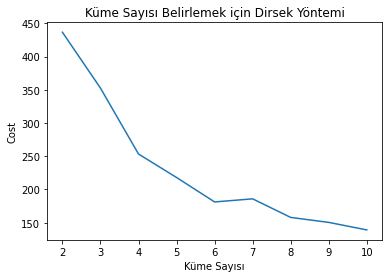

In [0]:
import matplotlib.pyplot as plt
plt.plot(k_number_list, cost_list)
plt.title('Küme Sayısı Belirlemek için Dirsek Yöntemi')
plt.xlabel('Küme Sayısı')
plt.ylabel('Cost')
plt.show()

In [0]:
# We have decides the k value now we can create kmeans model

In [0]:
kmeansObject = KMeans() \
        .setSeed(142) \
        .setK(6) \
        .setPredictionCol("cluster") \
        .setFeaturesCol("features") \
        .setMaxIter(40) \
        .setTol(1.0e-5)

In [0]:
pipeline_obj = Pipeline().setStages([gender_strx, num_features_vector_asm, scaler, all_features_vector_asm, kmeansObject])

In [0]:
pipeline_model_final = pipeline_obj.fit(df)

In [0]:
transformed_df_final = pipeline_model_final.transform(df)

In [0]:
transformed_df_final.limit(6).toPandas()

/databricks/spark/python/pyspark/sql/pandas/conversion.py:122: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  Unable to convert the field numeric_unscaled_features. If this column is not necessary, you may consider dropping it or converting to primitive type before the conversion.
Direct cause: Unsupported type in conversion to Arrow: VectorUDT()
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,CustomerID,Gender,Age,AnnualIncome,SpendingScore,gender_indexed,numeric_unscaled_features,num_scaled_features,features,cluster
0,1,Male,19,15000,39,1.0,"[19.0, 15000.0, 39.0]","[1.360153914235199, 0.5711082903036442, 1.5102...","[1.0, 1.360153914235199, 0.5711082903036442, 1...",0
1,2,Male,21,15000,81,1.0,"[21.0, 15000.0, 81.0]","[1.503328010470483, 0.5711082903036442, 3.1366...","[1.0, 1.503328010470483, 0.5711082903036442, 3...",0
2,3,Female,20,16000,6,0.0,"[20.0, 16000.0, 6.0]","[1.431740962352841, 0.6091821763238872, 0.2323...","[0.0, 1.431740962352841, 0.6091821763238872, 0...",2
3,4,Female,23,16000,77,0.0,"[23.0, 16000.0, 77.0]","[1.6465021067057672, 0.6091821763238872, 2.981...","[0.0, 1.6465021067057672, 0.6091821763238872, ...",0
4,5,Female,31,17000,40,0.0,"[31.0, 17000.0, 40.0]","[2.2191984916469036, 0.64725606234413, 1.54897...","[0.0, 2.2191984916469036, 0.64725606234413, 1....",2
5,6,Female,22,17000,76,0.0,"[22.0, 17000.0, 76.0]","[1.574915058588125, 0.64725606234413, 2.943053...","[0.0, 1.574915058588125, 0.64725606234413, 2.9...",0


In [0]:
transformed_df_final.groupBy("cluster").count().show()

+-------+-----+
|cluster|count|
+-------+-----+
|      1|   45|
|      3|   34|
|      5|   38|
|      4|   39|
|      2|   21|
|      0|   23|
+-------+-----+

